# Project 1: Uber/Lyft Ride Fare Estimator (Regression)

**Course:** Machine Learning, Chapter 14 Capstone Project

**Author:** Mozammel hoque sagor

## Objective
Predict the **fare of a taxi/ride-hailing trip** from where and when it starts and ends. This is a **regression** problem, because the target (`fare_amount`) is a continuous number.

## Dataset
NYC taxi / Uber fare data (CSV). This notebook expects these columns:

`fare_amount, pickup_datetime, pickup_longitude, pickup_latitude, dropoff_longitude, dropoff_latitude, passenger_count`

Put the CSV in the `data/` folder (default name `/content/uber.csv`) or change `DATA_PATH` below.

## Pipeline (matches the capstone guidelines)
| Step | Section |
|---|---|
| 1. Data acquisition & EDA | 1, 4 |
| 2. Preprocessing (missing values, outliers, scaling) | 2, 6 |
| 3. Feature engineering (distance, hour of day) | 3 |
| 4. Model selection: baseline + complex model | 6, 7 |
| 5. Hyperparameter tuning (RandomizedSearchCV) | 8 |
| 6. Rigorous evaluation (RMSE, MAE, R²) | 9 |


## 0. Setup

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def save_fig(name):
    """Save the current figure to figures/ (handy for the PDF report)."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")


In [ ]:
# ---- Settings you can change ----
DATA_PATH = os.environ.get("DATA_PATH", "/content/uber.csv")  # path to the CSV file
READ_ROWS = 200_000   # rows to read (None = whole file; the full NYC taxi file is huge)
TEST_SIZE = 0.2       # 20% of the data is kept for the final test
N_ITER = 8            # number of random-search trials
CV_FOLDS = 3          # cross-validation folds
TUNE_ROWS = 20_000    # tune on a subsample of the training set to save time


## 1. Data acquisition

In [ ]:
df = pd.read_csv(DATA_PATH, nrows=READ_ROWS)
print("Raw shape:", df.shape)

required = [
    "fare_amount", "pickup_datetime",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count",
]
absent = [c for c in required if c not in df.columns]
if absent:
    raise ValueError(f"Missing columns {absent}. Columns found: {list(df.columns)}")

df = df[required].copy()


Raw shape: (200000, 9)


In [ ]:
display(df.head())
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
display(df.describe().T)


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        200000 non-null  float64
 1   pickup_datetime    200000 non-null  object 
 2   pickup_longitude   200000 non-null  float64
 3   pickup_latitude    200000 non-null  float64
 4   dropoff_longitude  199999 non-null  float64
 5   dropoff_latitude   199999 non-null  float64
 6   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 10.7+ MB

Missing values per column:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
fare_amount,200000.0,11.359955,9.901776,-52.000000,6.000000,8.500000,12.500000,499.000000
pickup_longitude,200000.0,-72.527638,11.437787,-1340.648410,-73.992065,-73.981823,-73.967154,57.418457
pickup_latitude,200000.0,39.935885,7.720539,-74.015515,40.734796,40.752592,40.767158,1644.421482
dropoff_longitude,199999.0,-72.525292,13.117408,-3356.666300,-73.991407,-73.980093,-73.963658,1153.572603
dropoff_latitude,199999.0,39.923890,6.794829,-881.985513,40.733823,40.753042,40.768001,872.697628
passenger_count,200000.0,1.684535,1.385997,0.000000,1.000000,1.000000,2.000000,208.000000


**Look at the `min` and `max` columns above.** Real-world trip data is usually dirty: negative or zero fares, coordinates at (0, 0), impossible passenger counts. Check which of these problems appear in *your* file, then clean them in the next section.

## 2. Preprocessing & cleaning

In [ ]:
n_before = len(df)

# Parse the timestamp (bad values become NaT and are dropped below)
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)

# Missing values and duplicates
df = df.dropna().drop_duplicates()

# Plausible fares and passenger counts (the 200 USD cap is a judgement call)
df = df[(df["fare_amount"] > 0) & (df["fare_amount"] < 200)]
df = df[df["passenger_count"].between(1, 6)]

# Keep only trips inside a bounding box around New York City
lat_ok = lambda s: s.between(40.5, 41.0)
lon_ok = lambda s: s.between(-74.3, -73.6)
df = df[
    lat_ok(df["pickup_latitude"]) & lat_ok(df["dropoff_latitude"])
    & lon_ok(df["pickup_longitude"]) & lon_ok(df["dropoff_longitude"])
]

print(f"Rows kept: {len(df):,} of {n_before:,} ({len(df) / n_before:.1%})")


Rows kept: 194,915 of 200,000 (97.5%)


## 3. Feature engineering
Raw coordinates are hard for a model to use directly. Fare depends mostly on **how far** the trip is, so we compute:
- **Haversine distance** (km along the Earth's surface) between pickup and dropoff
- **Time features** (hour, weekday, month, year) in New York local time
- **Distance to the three big airports** (JFK, LaGuardia, Newark), because airport trips have special pricing

In [ ]:
AIRPORTS = {
    "jfk": (40.6413, -73.7781),
    "lga": (40.7769, -73.8740),
    "ewr": (40.6895, -74.1745),
}


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in kilometres between two lat/long points."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


def add_features(d):
    """Build model features from raw trip columns (also reused for the live demo)."""
    d = d.copy()
    local = pd.to_datetime(d["pickup_datetime"], utc=True).dt.tz_convert("America/New_York")
    d["hour"] = local.dt.hour
    d["dayofweek"] = local.dt.dayofweek
    d["month"] = local.dt.month
    d["year"] = local.dt.year
    d["is_weekend"] = (d["dayofweek"] >= 5).astype(int)
    d["distance_km"] = haversine_km(
        d["pickup_latitude"], d["pickup_longitude"],
        d["dropoff_latitude"], d["dropoff_longitude"],
    )
    for name, (lat, lon) in AIRPORTS.items():
        d[f"pickup_{name}_km"] = haversine_km(d["pickup_latitude"], d["pickup_longitude"], lat, lon)
        d[f"dropoff_{name}_km"] = haversine_km(d["dropoff_latitude"], d["dropoff_longitude"], lat, lon)
    return d


df = add_features(df)
df = df[df["distance_km"] > 0.1]   # drop trips with (almost) zero distance

TARGET = "fare_amount"
FEATURES = [
    "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "distance_km",
    "hour", "dayofweek", "month", "year", "is_weekend",
    "pickup_jfk_km", "dropoff_jfk_km", "pickup_lga_km", "dropoff_lga_km",
    "pickup_ewr_km", "dropoff_ewr_km",
]
print(f"Final dataset: {len(df):,} rows, {len(FEATURES)} features")


Final dataset: 191,801 rows, 17 features


## 4. Exploratory data analysis (EDA)

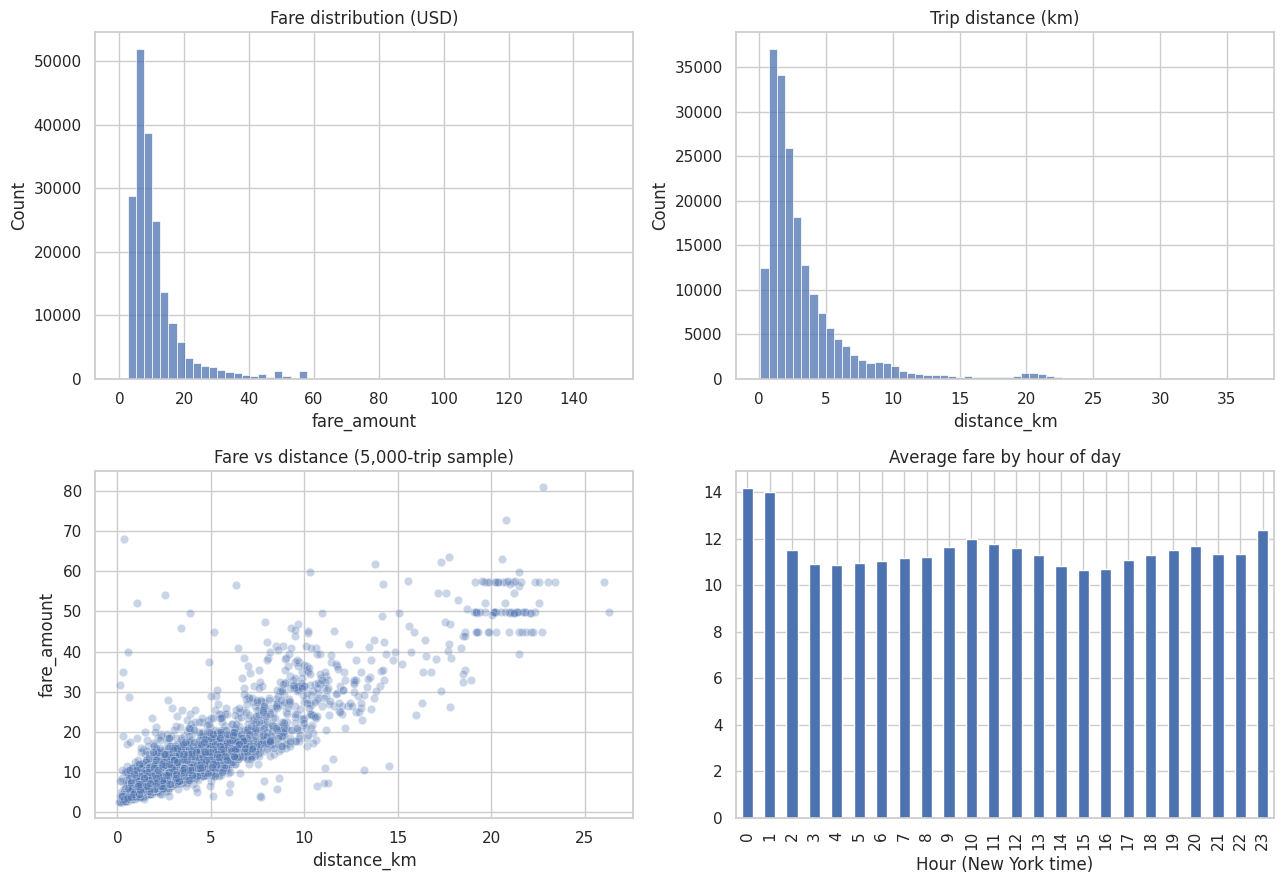

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df[TARGET], bins=60, ax=ax[0, 0])
ax[0, 0].set_title("Fare distribution (USD)")

sns.histplot(df["distance_km"], bins=60, ax=ax[0, 1])
ax[0, 1].set_title("Trip distance (km)")

sample = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="distance_km", y=TARGET, alpha=0.3, ax=ax[1, 0])
ax[1, 0].set_title("Fare vs distance (5,000-trip sample)")

df.groupby("hour")[TARGET].mean().plot(kind="bar", ax=ax[1, 1])
ax[1, 1].set_title("Average fare by hour of day")
ax[1, 1].set_xlabel("Hour (New York time)")

save_fig("uber_eda_overview")
plt.show()


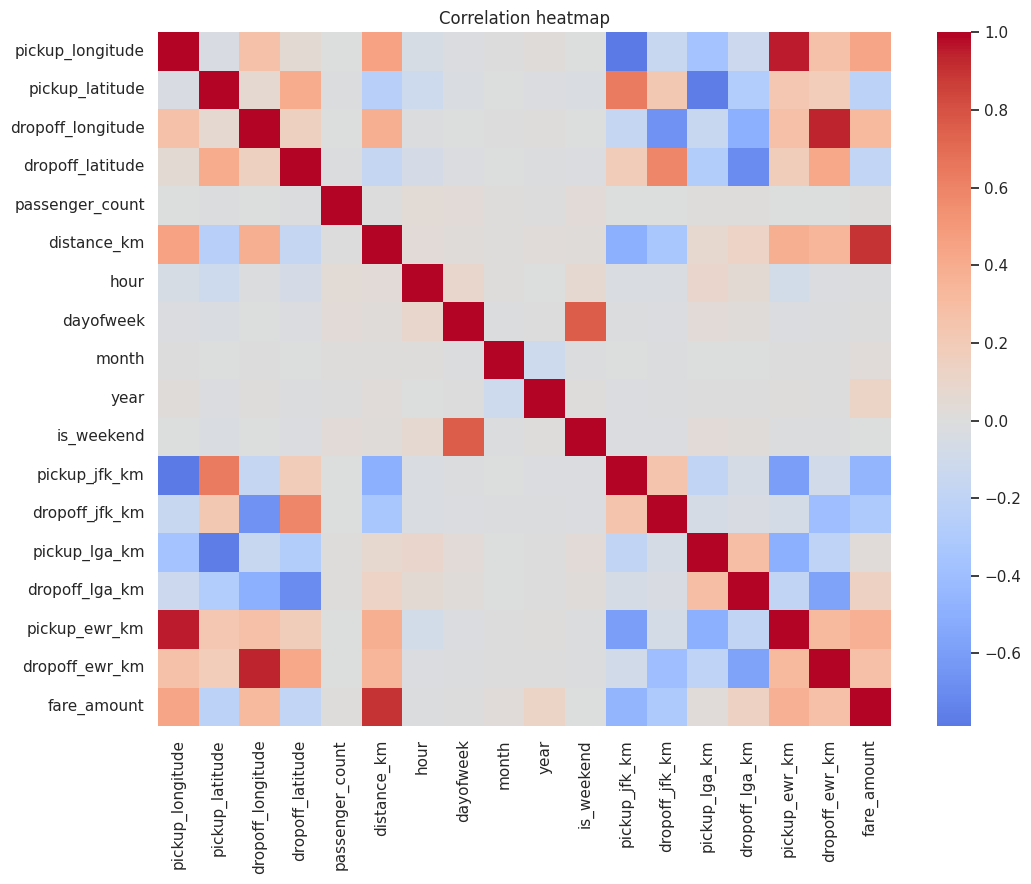

distance_km          0.899
pickup_longitude     0.440
pickup_ewr_km        0.375
dropoff_longitude    0.319
dropoff_ewr_km       0.281
dropoff_lga_km       0.142
year                 0.125
pickup_lga_km        0.027
month                0.025
passenger_count      0.014
dayofweek            0.007
is_weekend           0.000
hour                -0.008
dropoff_latitude    -0.183
pickup_latitude     -0.219
dropoff_jfk_km      -0.306
pickup_jfk_km       -0.459
Name: fare_amount, dtype: float64


In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FEATURES + [TARGET]].corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
save_fig("uber_correlation_heatmap")
plt.show()

print(df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3))


### EDA insights
- *Insight 1:* Distance is by far the strongest predictor. Its correlation with fare is 0.899, and the Random Forest also gives it the largest importance (about 0.41). Fare grows roughly in a straight line with distance for normal trips.
- *Insight 2:* Fares and distances are right-skewed. Most trips are short and cheap, with a long tail of expensive trips. In the fare-vs-distance plot, some long trips (around 20 km) sit at nearly flat fares of about 45 to 57 USD, which may be airport flat fares (my guess, not checked).
- *Insight 3:* Average fare is highest around midnight (hours 0 and 1, about 14 USD) and lower at other hours (about 11 to 12 USD). Hour has only a small effect overall, and weekday, weekend and passenger count are close to unimportant.

## 5. Train / test split
We split **before** fitting anything, so the test set stays completely unseen. A random split is fine here because individual trips are independent of each other (a time-series forecast would need a time-ordered split instead).

In [ ]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (153440, 17) | Test: (38361, 17)


## 6. Baseline model: Linear Regression
Scaling goes **inside a Pipeline**, so the scaler learns its mean and standard deviation from the training data only (no leakage from the test set).

In [ ]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def evaluate(name, model):
    p_train, p_test = model.predict(X_train), model.predict(X_test)
    return {
        "Model": name,
        "Train RMSE": rmse(y_train, p_train),
        "Test RMSE": rmse(y_test, p_test),
        "Test MAE": mean_absolute_error(y_test, p_test),
        "Test R2": r2_score(y_test, p_test),
    }


results = []

baseline = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
baseline.fit(X_train, y_train)
results.append(evaluate("Linear Regression (baseline)", baseline))
display(pd.DataFrame(results).round(3))


,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Linear Regression (baseline),3.919,3.832,2.123,0.831


## 7. Complex model: Random Forest
A Random Forest averages many decision trees and can learn non-linear patterns (for example the flat airport fares) that a straight line cannot. Trees don't need feature scaling.

In [ ]:
rf_default = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf_default.fit(X_train, y_train)
results.append(evaluate("Random Forest (default)", rf_default))
display(pd.DataFrame(results).round(3))


,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Linear Regression (baseline),3.919,3.832,2.123,0.831
1,Random Forest (default),1.216,3.085,1.627,0.891


## 8. Hyperparameter tuning (RandomizedSearchCV)
We search for good settings using cross-validation **on the training data only**. To keep it fast, the search runs on a subsample of the training set; the best settings are then used to retrain on the full training set.

In [ ]:
tune_idx = X_train.sample(min(TUNE_ROWS, len(X_train)), random_state=RANDOM_STATE).index
X_tune, y_tune = X_train.loc[tune_idx], y_train.loc[tune_idx]

param_dist = {
    "n_estimators": [50, 100, 150],
    "max_depth": [8, 12, 16, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", 0.5],
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=CV_FOLDS,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
)
search.fit(X_tune, y_tune)

print("Best parameters:", search.best_params_)
print(f"Best cross-validated RMSE: {-search.best_score_:.3f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'n_estimators': 150, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
Best cross-validated RMSE: 3.172


In [ ]:
best_rf = RandomForestRegressor(**search.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
best_rf.fit(X_train, y_train)
results.append(evaluate("Random Forest (tuned)", best_rf))


## 9. Rigorous evaluation
- **RMSE**: typical size of the error in USD (punishes big mistakes more)
- **MAE**: average absolute error in USD
- **R²**: share of the fare variation the model explains (1.0 = perfect)

Compare **Train RMSE vs Test RMSE**: a much lower train error means overfitting.

,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Linear Regression (baseline),3.919,3.832,2.123,0.831
1,Random Forest (default),1.216,3.085,1.627,0.891
2,Random Forest (tuned),1.765,2.998,1.562,0.897


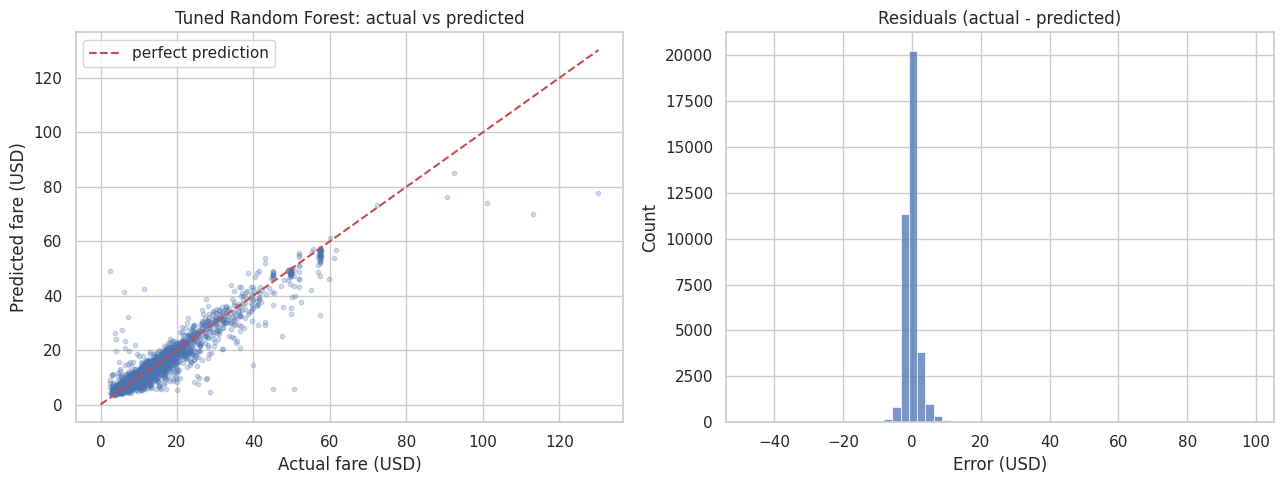

In [ ]:
results_df = pd.DataFrame(results).round(3)
display(results_df)

pred = best_rf.predict(X_test)
residuals = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
idx = np.random.RandomState(RANDOM_STATE).choice(len(y_test), size=min(5000, len(y_test)), replace=False)
ax[0].scatter(y_test.values[idx], pred[idx], alpha=0.25, s=10)
lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--", label="perfect prediction")
ax[0].set_xlabel("Actual fare (USD)")
ax[0].set_ylabel("Predicted fare (USD)")
ax[0].set_title("Tuned Random Forest: actual vs predicted")
ax[0].legend()

sns.histplot(residuals, bins=60, ax=ax[1])
ax[1].set_title("Residuals (actual - predicted)")
ax[1].set_xlabel("Error (USD)")

save_fig("uber_evaluation")
plt.show()


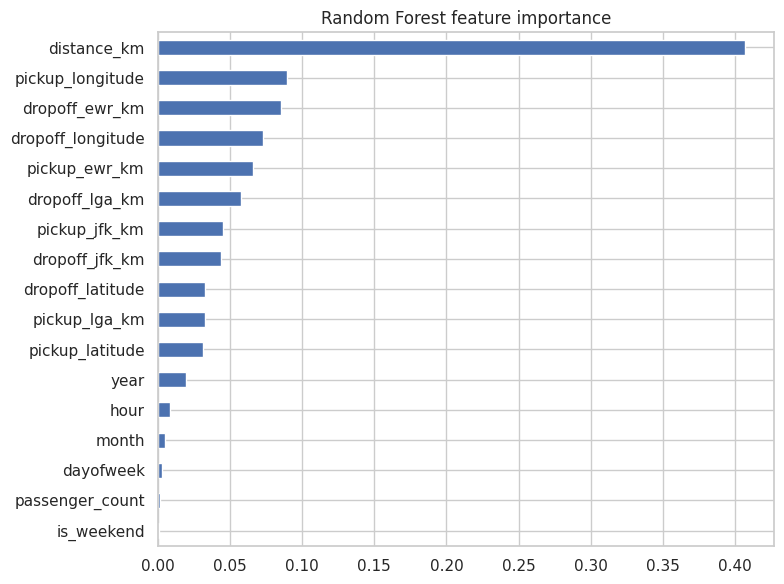

In [ ]:
importances = pd.Series(best_rf.feature_importances_, index=FEATURES).sort_values()
importances.plot(kind="barh", figsize=(8, 6), title="Random Forest feature importance")
save_fig("uber_feature_importance")
plt.show()


## 10. Live demo: predict a new trip
This is the "live demo" slide of the presentation: type in a trip and get a fare estimate.

In [ ]:
def predict_fare(pickup, dropoff, when_utc, passengers=1):
    """pickup / dropoff are (latitude, longitude); when_utc is a UTC timestamp string."""
    trip = pd.DataFrame({
        "pickup_datetime": [pd.Timestamp(when_utc, tz="UTC")],
        "pickup_latitude": [pickup[0]], "pickup_longitude": [pickup[1]],
        "dropoff_latitude": [dropoff[0]], "dropoff_longitude": [dropoff[1]],
        "passenger_count": [passengers],
    })
    return float(best_rf.predict(add_features(trip)[FEATURES])[0])


demo_year = int(df["year"].max())   # stay inside the years the model has seen
times_square, jfk = (40.7580, -73.9855), (40.6413, -73.7781)
fare = predict_fare(times_square, jfk, f"{demo_year}-06-03 16:30:00")
print(f"Times Square -> JFK, estimated fare: ${fare:.2f}")


Times Square -> JFK, estimated fare: $55.63


## 11. Conclusion
- **Which model won, and by how much?** The tuned Random Forest was best: Test RMSE 2.998, MAE 1.562 and R² 0.897. The Linear Regression baseline had Test RMSE 3.832 and R² 0.831, so the tuned forest cut RMSE by about 22%. Tuning helped only a little over the default forest (RMSE 3.085).
- **What does the error mean in practice?** On average the estimate is off by about 1.56 USD (MAE). Larger mistakes happen too, as shown by the RMSE of about 3 USD.
- **Limitations:** The training error (1.765) is lower than the test error (2.998), so there is some overfitting. There is no traffic or weather data, the data covers several years of changing fares, the tuning used only 8 random trials on a 20,000-row sample, and long trips such as airport rides are harder to predict.
- **Future work:** Add traffic and weather, try XGBoost, search more settings, and deploy the model with FastAPI.